<a href="https://colab.research.google.com/github/a01770768-oss/JobishViri/blob/main/Clase5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Ice-cream Costumer Satisfaction Analysis**


TABLE OF Contents:

1. [Initial Setup](#scrollTo=4r9GGTtviT1z)
2. [RQ1 : Which age gruop represents largest share of respondents?](#scrollTo=81W_lDTWlPnc)
3.

[1. Initial Setup](#scrollTo=mod4XFq6h8Su)

[RQ1 : Which age gruop represents largest share of respondents?](#scrollTo=mod4XFq6h8Su)

In [ ]:
file_path = 'https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/satis.csv'
import pandas as pd
df = pd.read_csv(file_path)
df.head()

,Age,Gender,Ocupation,Monthly income,Price,Quality,Quantity,Availability,Taste,Flavours,...,Overal satisfaction,Consistency,Factor,Frowned,reason,Popular,My favorite,Kind,Preference,Recommend
0,33.0,Male,Research,">40, 000",5.0,5.0,5.0,4.0,4.0,5.0,...,4.0,4.0,Taste,No,NaN,Combo_VLM,Chocolate,More than one flavoured,agree,agree
1,39.0,Male,student,"<10,000",3.0,5.0,3.0,4.0,5.0,5.0,...,4.0,4.0,Taste,No,Quantity issues,Combo_VCS,Chocolate,More than one flavoured,neutral,neutral
2,40.0,Female,Teaching,">40, 000",3.0,4.0,4.0,4.0,3.0,4.0,...,4.0,4.0,Taste,No,NaN,Combo_VCS,Caramel,More than one flavoured,disagree,neutral
3,27.0,Male,Student,"<10,000",5.0,5.0,3.0,4.0,5.0,5.0,...,4.0,4.0,Taste,No,NaN,Combo_VCS,Strawbery,More than one flavoured,agree,agree
4,23.0,Female,Tutor,"10,000 - 20,000",5.0,5.0,4.0,4.0,5.0,5.0,...,5.0,5.0,Quality,No,NaN,Combo_VCS,Vanila,single flavoured,agree,Strongly agree


In [ ]:
df.columns

Index(['Age', 'Gender', 'Ocupation', 'Monthly income', 'Price', 'Quality',
       'Quantity', 'Availability', 'Taste', 'Flavours', 'Customer relation',
       'Customer services', 'Texture', 'Size', 'Overal satisfaction',
       'Consistency', 'Factor', 'Frowned', 'reason', 'Popular', 'My favorite',
       'Kind', 'Preference', 'Recommend'],
      dtype='object')

In [ ]:
favs = ['Age', 'Gender', 'Price', 'Quality',]

In [ ]:
ndf = df[favs]
ndf.head()

,Age,Gender,Price,Quality
0,33.0,Male,5.0,5.0
1,39.0,Male,3.0,5.0
2,40.0,Female,3.0,4.0
3,27.0,Male,5.0,5.0
4,23.0,Female,5.0,5.0


Description of **DATASET**

This Dataset gives the satisfaction survey results of an icecream company. Each Row gives reply of each costumer.

Description of the Variables of Interest



* Age : This variable gives the age of the costumer, Its a numerical variable
* Gender:
* Price: Gives the satisfaction on price of each
* Quality:



In [ ]:
ndf.shape

(55, 4)

In [ ]:
ndf = ndf.dropna()


In [ ]:
ndf.isnull().any()

RQ1

In [ ]:
def cus_cls(x):
  if 0 <= x < 20:
    return '0 - 20'
  elif 20 <= x < 30:
    return '21 - 30'
  elif 30 <= x < 40:
    return '31 - 40'
  return '>=40'

In [ ]:
df.Age.describe()

,Age
count,50.00000
mean,26.02000
std,7.23791
min,15.00000
25%,21.00000
50%,24.50000
75%,29.00000
max,48.00000


In [ ]:
cus_cls(0)

'0 - 20'

In [ ]:
cus_cls(20)

'21 - 30'

In [ ]:
ndf['AgeGP'] = ndf['Age'].apply(cus_cls)
ndf.head()

/tmp/ipykernel_695/4196775617.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ndf['AgeGP'] = ndf['Age'].apply(cus_cls)


,Age,Gender,Price,Quality,AgeGP
0,33.0,Male,5.0,5.0,31 - 40
1,39.0,Male,3.0,5.0,31 - 40
2,40.0,Female,3.0,4.0,>=40
3,27.0,Male,5.0,5.0,21 - 30
4,23.0,Female,5.0,5.0,21 - 30


In [ ]:
age_gp_counts = pd.pivot_table(ndf, index='AgeGP',
            values = 'Price',
            aggfunc='count')
age_gp_counts

,Price
AgeGP,
0 - 20,8
21 - 30,30
31 - 40,9
>=40,3


In [ ]:
new_names = {'Price':'count_AgeGP'}
age_gp_counts.rename(columns=new_names,
                     inplace=True)
age_gp_counts.reset_index(inplace=True)
age_gp_counts

,AgeGP,count_AgeGP
0,0 - 20,8
1,21 - 30,30
2,31 - 40,9
3,>=40,3


In [ ]:
import matplotlib.pyplot as plt


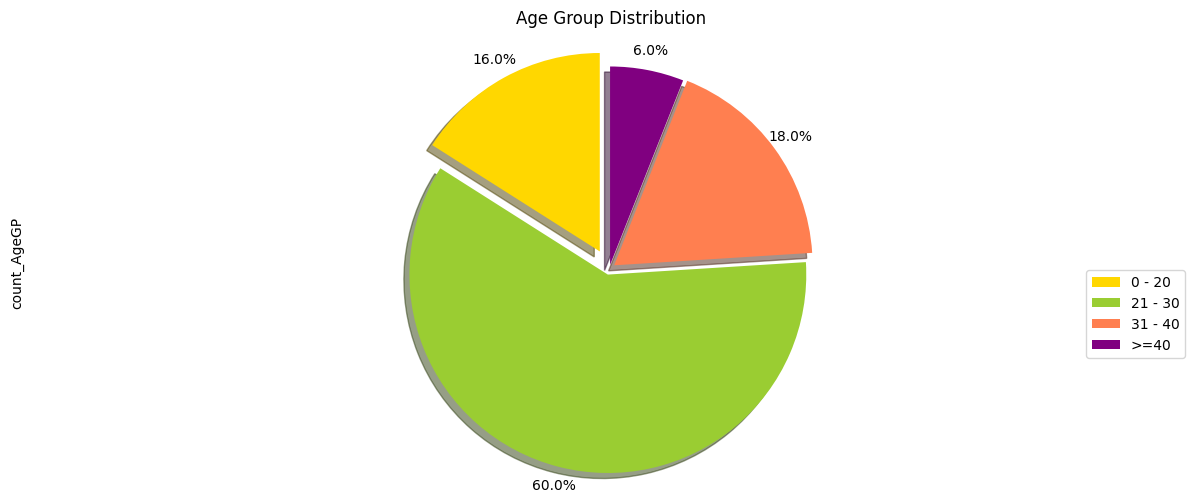

In [ ]:
import matplotlib.pyplot as plt
from numpy import exp
explode_list = [0.1,0.03,0.03,0.02]
colors= ['gold','yellowgreen','coral','purple']

age_gp_counts['count_AgeGP'].plot(kind='pie',
                                  figsize=(15,6),
                                  autopct = '%1.1f%%',
                                  startangle = 90,
                                  shadow = True,
                                  labels = None,
                                  pctdistance = 1.1,
                                  explode = explode_list,
                                  colors = colors
                                  )

plt.axis('equal')
plt.legend(labels= age_gp_counts.AgeGP,
           bbox_to_anchor = (1,0.5))
plt.title('Age Group Distribution')
plt.show()

<details><summary><strong> Insights: </strong></summary>

1. Mayority of my clientele belongs to age group 21-30, and least belongs to >=40

</details>